# 04 · Accessibility index, clustering, spatial analysis and ML
**RuralReach** – from validated indicators to decisions.

1. **RuralReach Accessibility Index (RAI, 0-100)** – four pillars, transparent weights, winsorised scaling.
2. **Robustness** – do rankings survive different weighting schemes?
3. **Priority groups** – rural dependence × accessibility.
4. **Clusters** – K-Means district typologies (validated against Ward hierarchical clustering).
5. **Spatial autocorrelation** – global/local Moran's I (hot & cold spots).
6. **ML** – can structural features predict literacy, and how badly does *random* CV overstate it vs. *state-held-out* CV?

In [1]:
import sys, warnings, json
from pathlib import Path
_p = Path.cwd().resolve()
while not (_p / "src" / "rr_utils.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))
from rr_utils import *
import geopandas as gpd
import matplotlib.pyplot as plt, matplotlib as mpl, seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.neighbors import BallTree
warnings.filterwarnings("ignore")

PAL = dict(primary="#1f6f78", accent="#e07a1f", muted="#8a9aa3", bad="#b5382a", good="#2f8f5b", ink="#1d2b32")
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 140, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlesize": 12, "axes.edgecolor": "#9aa7ad", "axes.labelcolor": PAL["ink"], "text.color": PAL["ink"], "axes.grid": True,
                     "grid.color": "#e6ebee", "grid.linewidth": .8, "axes.axisbelow": True})
def save(fig, name): fig.savefig(ASSETS / f"{name}.png", bbox_inches="tight", facecolor="white")
RNG = 42
df = pd.read_csv(FINAL / "RuralReach_Master_base.csv")
geo = gpd.read_file(FINAL / "RuralReach_Districts.gpkg")
print(df.shape)

(640, 82)


## 1 · The RuralReach Accessibility Index
**Method (documented, reproducible)**
* every indicator is oriented so *higher = better access* (`distance` is inverted);
* skewed counts get `log1p`;
* each indicator is **winsorised min-max scaled** to 0-100 between its 5th and 95th percentile, so that metros/islands do not compress everyone else;
* a pillar = mean of its available indicators (a missing indicator is *skipped*, never treated as 0);
* RAI = weighted mean of the pillars.

| Pillar | Weight | Indicators | Resolution |
|---|---|---|---|
| Education | 0.30 | effective literacy, secondary-education share, graduate share | district |
| Transport | 0.30 | distance to nearest active station (inv.), station density, trains serving | district |
| Health | 0.20 | PHC-doctor staffing %, PHC doctors per 100 k | **state** (2017) |
| Livelihood | 0.20 | non-farm share of workers | district |

*Digital* and *Market* pillars of the guide cannot be built from the supplied data (no district internet/mobile/banking fields;
mandi data cover 24 % of districts) – mandi is reported as supporting evidence only.

In [2]:
def wscale(s, invert=False, log=False, lo=5, hi=95):
    x = np.log1p(s) if log else s.astype(float)
    a, b = np.nanpercentile(x, [lo, hi])
    z = ((x - a) / (b - a)).clip(0, 1) * 100
    return 100 - z if invert else z

d = df.copy()
d["NonFarm_Worker_Share"] = 100 - d.Farm_Worker_Share          # household-industry + other workers (everything that is not cultivation / agricultural labour)
IND = {
    "Education": {"Literacy_Rate_Effective": dict(), "Secondary_Edu_pct": dict(), "Graduate_pct": dict(log=True)},
    "Transport": {"Nearest_Railway_km": dict(invert=True, log=True), "Stations_per_1000sqkm": dict(log=True), "Trains_Serving": dict(log=True)},
    "Health": {"StateLvl_PHC_Doctor_Staffing_pct": dict(), "StateLvl_PHC_Doctors_per_100k": dict(log=True)},
    "Livelihood": {"NonFarm_Worker_Share": dict()},
}
W = {"Education": .30, "Transport": .30, "Health": .20, "Livelihood": .20}
scaled = {}
for pillar, inds in IND.items():
    for col, kw in inds.items():
        scaled[col] = wscale(d[col], **kw)
S = pd.DataFrame(scaled)
for pillar, inds in IND.items():
    d[f"{pillar}_Access_Score"] = S[list(inds)].mean(axis=1, skipna=True)
P = [f"{p}_Access_Score" for p in IND]
def rai(weights, frame=d):
    w = pd.Series(weights); w.index = [f"{p}_Access_Score" for p in w.index]
    num = frame[w.index].mul(w).sum(axis=1, min_count=1)
    den = frame[w.index].notna().mul(w).sum(axis=1)
    return num / den
d["Overall_Accessibility_Index"] = rai(W)
d["RAI_Rank"] = d.Overall_Accessibility_Index.rank(ascending=False, method="min").astype(int)
print(d[P + ["Overall_Accessibility_Index"]].describe().round(1).T)
print("\nTop 10 / bottom 10 districts")
cols = ["State_name", "District_name", "Overall_Accessibility_Index"] + P
print(d.nlargest(10, "Overall_Accessibility_Index")[cols].round(1).to_string(index=False))
print(d.nsmallest(10, "Overall_Accessibility_Index")[cols].round(1).to_string(index=False))

                             count  mean   std  min   25%   50%   75%    max
Education_Access_Score       640.0  47.8  25.5  0.0  28.1  46.5  67.4  100.0
Transport_Access_Score       640.0  54.5  28.7  0.0  39.8  62.3  76.7  100.0
Health_Access_Score          640.0  56.6  28.2  1.8  33.6  60.9  79.5  100.0
Livelihood_Access_Score      640.0  35.9  28.5  0.0  14.5  28.1  51.8  100.0
Overall_Accessibility_Index  640.0  49.2  17.8  1.9  36.3  47.6  60.6   95.9

Top 10 / bottom 10 districts
    State_name      District_name  Overall_Accessibility_Index  Education_Access_Score  Transport_Access_Score  Health_Access_Score  Livelihood_Access_Score
    TAMIL NADU            Chennai                         95.9                    98.1                   100.0                 82.3                    100.0
        KERALA Thiruvananthapuram                         93.8                   100.0                    92.7                 79.7                    100.0
   MAHARASHTRA             Mumbai    

### Sanity checks
* **Internal consistency** – do pillar scores correlate positively but not perfectly (otherwise a single pillar would suffice)?
* **Face validity** – do known well-served districts rank high?

In [3]:
pc = d[P].corr(method="spearman").round(2)
print(pc)
ref = ["Kolkata", "Mumbai", "Chennai", "Ernakulam", "Pune", "Thiruvananthapuram"]
print("\nrank of reference districts:", d[d.District_name.isin(ref)][["District_name", "RAI_Rank"]].values.tolist())

                         Education_Access_Score  Transport_Access_Score  \
Education_Access_Score                     1.00                    0.23   
Transport_Access_Score                     0.23                    1.00   
Health_Access_Score                        0.28                   -0.35   
Livelihood_Access_Score                    0.63                    0.32   

                         Health_Access_Score  Livelihood_Access_Score  
Education_Access_Score                  0.28                     0.63  
Transport_Access_Score                 -0.35                     0.32  
Health_Access_Score                     1.00                     0.29  
Livelihood_Access_Score                 0.29                     1.00  

rank of reference districts: [['Kolkata', 29], ['Mumbai', 3], ['Pune', 42], ['Ernakulam', 7], ['Thiruvananthapuram', 2], ['Chennai', 1]]


**Reading.** The top of the ranking is the large southern/western metros and Kerala's coastal districts (Chennai, Thiruvananthapuram, Mumbai, Hyderabad, Bangalore, Ernakulam) - plausible.
The bottom is dominated by **Chhattisgarh's Bastar region** (Narayanpur, Bijapur, Kabeerdham, Kanker, Jashpur), **western Madhya Pradesh** (Alirajpur, Barwani), south **Odisha** (Malkangiri, Nabarangapur) and **Shrawasti** (UP) - tribal, forested, low-literacy districts with few trains.
Pillar correlations are moderate (Transport and Health only ~0.2-0.3 with the others), confirming the pillars carry *different* information; Education and Livelihood move together (0.63).

## 2 · Robustness of the ranking
Weights are a judgement. We test **(a)** equal weights, **(b)** data-driven PCA weights, **(c)** 2,000 random Dirichlet weightings,
**(d)** leaving out each pillar. A good index keeps its ranking.

equal weights      0.986
PCA loadings       0.948
drop Education     0.919
drop Transport     0.855
drop Health        0.934
drop Livelihood    0.967

random weights (n=2000): Spearman rho median 0.898, 5th pct 0.660; top-quartile overlap median 0.83
PCA weights: {'Education': np.float64(0.35), 'Transport': np.float64(0.12), 'Health': np.float64(0.17), 'Livelihood': np.float64(0.35)} | PC1 explains 47% of pillar variance


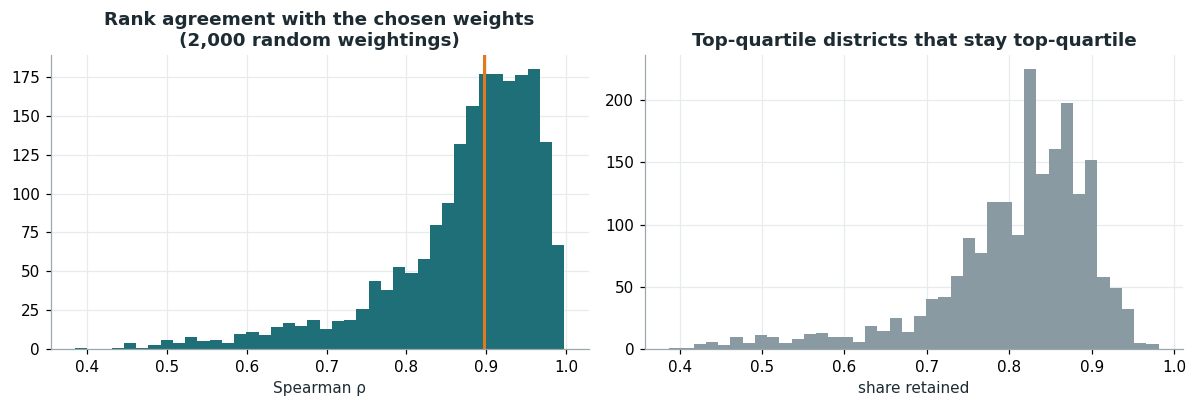

In [4]:
base = d.Overall_Accessibility_Index
variants = {"equal weights": rai({p: .25 for p in IND})}
Z = d[P].fillna(d[P].median())
pca = PCA(1).fit(StandardScaler().fit_transform(Z)); pw = np.abs(pca.components_[0]); pw = pw / pw.sum()
variants["PCA loadings"] = rai(dict(zip(IND, pw)))
for p in IND:
    variants[f"drop {p}"] = rai({q: (0 if q == p else W[q]) for q in IND})
rho = {k: stats.spearmanr(base, v)[0] for k, v in variants.items()}
rs = np.random.default_rng(RNG)
rd, flips = [], []
topq = base >= base.quantile(.75)
for w in rs.dirichlet(np.ones(4), 2000):
    v = rai(dict(zip(IND, w)))
    rd.append(stats.spearmanr(base, v)[0]); flips.append(((v >= v.quantile(.75)) & topq).sum() / topq.sum())
print(pd.Series(rho).round(3).to_string())
print(f"\nrandom weights (n=2000): Spearman rho median {np.median(rd):.3f}, 5th pct {np.percentile(rd, 5):.3f}; top-quartile overlap median {np.median(flips):.2f}")
print("PCA weights:", dict(zip(IND, pw.round(2))), "| PC1 explains %.0f%% of pillar variance" % (pca.explained_variance_ratio_[0] * 100))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(rd, bins=40, color=PAL["primary"]); ax[0].axvline(np.median(rd), color=PAL["accent"], lw=2)
ax[0].set_title("Rank agreement with the chosen weights\n(2,000 random weightings)"); ax[0].set_xlabel("Spearman ρ")
ax[1].hist(flips, bins=40, color=PAL["muted"]); ax[1].set_title("Top-quartile districts that stay top-quartile"); ax[1].set_xlabel("share retained")
fig.tight_layout(); save(fig, "idx_robustness"); plt.show()

**Reading.** Rankings are **stable under reasonable re-weighting**: equal weights rho = 0.99, PCA weights rho = 0.95, random weights median rho = 0.90 (5th percentile 0.66), and ~83 % of top-quartile districts stay top-quartile.
The index is most sensitive to the **Transport** pillar (dropping it lowers rho to 0.86) because it is the only pillar that varies strongly at *district* level inside a state.

## 3 · Priority groups – where is rural *and* poorly served?
Rurality = `Farm_Worker_Share` (above national district median ⇒ rural-dependent). Access tier from RAI quartiles.

In [5]:
rural = d.Farm_Worker_Share >= d.Farm_Worker_Share.median()
q1, q3 = d.Overall_Accessibility_Index.quantile([.25, .75])
tier = np.where(d.Overall_Accessibility_Index <= q1, "Low", np.where(d.Overall_Accessibility_Index >= q3, "High", "Medium"))
d["Access_Tier"] = tier
def group(r, t):
    if r and t == "Low": return "1 - Critical gap (rural & low access)"
    if (r and t == "Medium") or ((not r) and t == "Low"): return "2 - High priority"
    if ((not r) and t == "Medium") or (r and t == "High"): return "3 - Monitor"
    return "4 - Well served"
d["Priority_Group"] = [group(r, t) for r, t in zip(rural, tier)]
pg = d.groupby("Priority_Group").agg(districts=("District_ID", "size"), population_m=("Population", lambda s: s.sum() / 1e6),
                                      mean_RAI=("Overall_Accessibility_Index", "mean")).round(1)
print(pg)
print("\nCritical-gap districts by state:")
print(d[d.Priority_Group.str.startswith("1")].State_Current.value_counts().head(10).to_string())

                                       districts  population_m  mean_RAI
Priority_Group                                                          
1 - Critical gap (rural & low access)        146         188.1      27.4
2 - High priority                            178         346.7      45.0
3 - Monitor                                  166         309.1      50.7
4 - Well served                              150         366.8      73.6

Critical-gap districts by state:
State_Current
MADHYA PRADESH       28
UTTAR PRADESH        23
ODISHA               15
CHHATTISGARH         15
BIHAR                11
JHARKHAND            10
UTTARAKHAND           7
RAJASTHAN             6
NAGALAND              6
ARUNACHAL PRADESH     5


**Reading.** 146 districts (~188 M people in 2011) combine high rural dependence with bottom-quartile access.
They concentrate in **Madhya Pradesh, Uttar Pradesh, Odisha, Chhattisgarh, Bihar and Jharkhand**, with a smaller north-eastern/Himalayan tail (Nagaland, Arunachal, Uttarakhand).

## 4 · Spatial autocorrelation (Moran's I)
Do low-access districts cluster geographically? Weights = 8 nearest neighbours on centroids (row-standardised);
significance by 999 permutations. Local Moran (LISA) labels **hot spots (HH)**, **cold spots (LL)** and spatial outliers.

In [6]:
def knn_w(lat, lon, k=8):
    tree = BallTree(np.radians(np.c_[lat, lon]), metric="haversine")
    _, ix = tree.query(np.radians(np.c_[lat, lon]), k=k + 1)
    return ix[:, 1:]
NB = knn_w(d.Latitude.values, d.Longitude.values, 8)
def moran(x, nb, perms=999, seed=RNG):
    x = np.asarray(x, float); z = (x - x.mean()) / x.std()
    lag = z[nb].mean(axis=1)
    I = (z * lag).mean()
    rs_ = np.random.default_rng(seed)
    sims = np.array([(z * (rs_.permutation(z)[nb].mean(axis=1))).mean() for _ in range(perms)])
    p = (np.sum(np.abs(sims) >= abs(I)) + 1) / (perms + 1)
    return I, p, z, lag
def lisa(z, nb, perms=499, seed=RNG):
    n = len(z); lag = z[nb].mean(axis=1); Ii = z * lag
    rs_ = np.random.default_rng(seed); ps = np.empty(n)
    for i in range(n):
        others = np.delete(np.arange(n), i)
        sims = np.array([z[rs_.choice(others, nb.shape[1], replace=False)].mean() * z[i] for _ in range(perms)])
        ps[i] = (np.sum(np.abs(sims) >= abs(Ii[i])) + 1) / (perms + 1)
    return ps
res = {}
for name, col in [("Overall_Accessibility_Index", "RAI"), ("Literacy_Rate_Effective", "Literacy"), ("Transport_Access_Score", "Transport")]:
    s = d[col if False else name].fillna(d[name].median())
    I, p, z, lag = moran(s, NB); res[name] = (I, p)
    print(f"Moran's I  {name:30s} I = {I:.3f}  p = {p:.3f}")
I, p, z, lag = moran(d.Overall_Accessibility_Index, NB)
ps = lisa(z, NB)
lab = np.where(ps >= .05, "Not significant", np.where((z > 0) & (lag > 0), "High-High (hot spot)", np.where((z < 0) & (lag < 0), "Low-Low (cold spot)",
               np.where((z > 0) & (lag < 0), "High-Low outlier", "Low-High outlier"))))
d["LISA_Cluster"] = lab
print(pd.Series(lab).value_counts().to_string())

Moran's I  Overall_Accessibility_Index    I = 0.536  p = 0.001
Moran's I  Literacy_Rate_Effective        I = 0.623  p = 0.001
Moran's I  Transport_Access_Score         I = 0.475  p = 0.001


Not significant         423
High-High (hot spot)    124
Low-Low (cold spot)      73
Low-High outlier         11
High-Low outlier          9


**Reading.** Moran's I = **0.54** for the RAI (0.62 for literacy): low-access districts cluster spatially (p = 0.001).
LISA marks a contiguous **cold spot** across Chhattisgarh - Odisha - Jharkhand - eastern MP, a second one along the western MP / southern Rajasthan border and a third along the Nepal-border districts of UP/Bihar; **hot spots** cover the southern peninsula (Kerala-Karnataka-Tamil Nadu), the Punjab-Haryana-Himachal belt and coastal Odisha.
Spatially contiguous deprivation argues for **regional programmes** rather than district-by-district fixes.

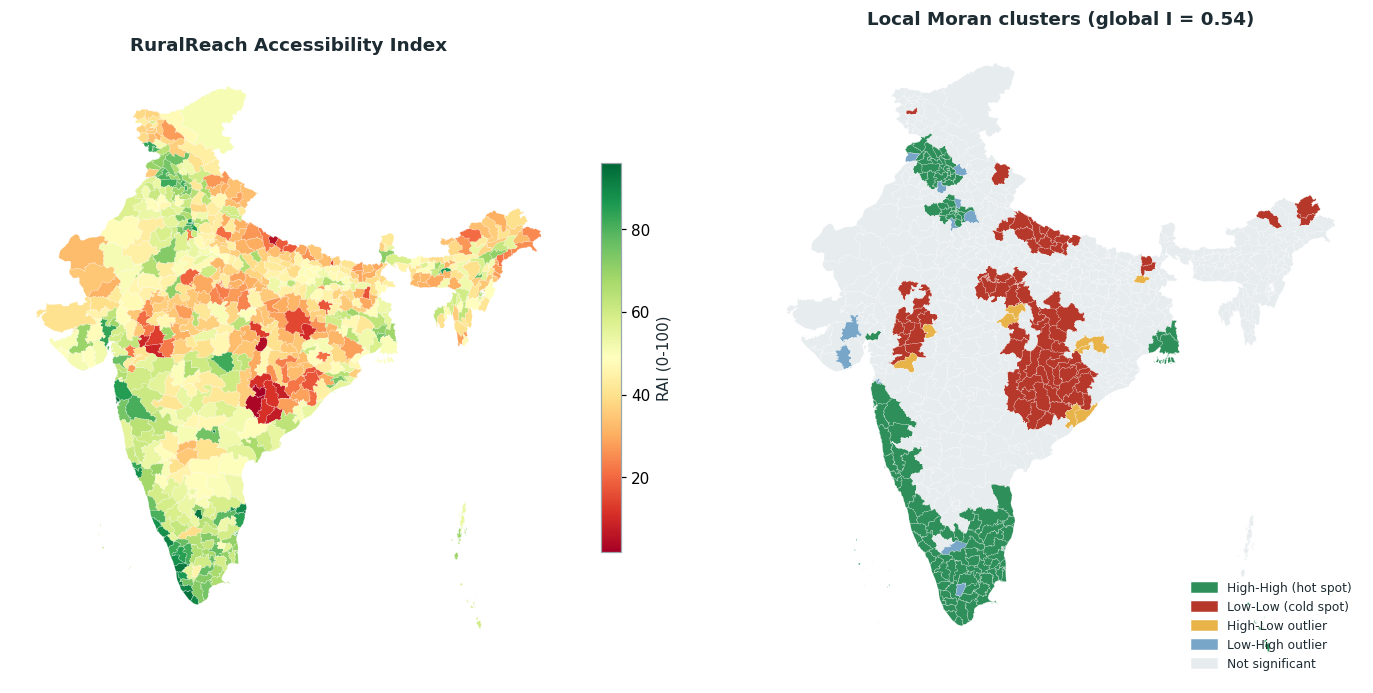

In [7]:
cmap = {"High-High (hot spot)": PAL["good"], "Low-Low (cold spot)": PAL["bad"], "High-Low outlier": "#e8b44a", "Low-High outlier": "#78a6c8", "Not significant": "#e7ecef"}
g2 = geo.merge(d[["District_ID", "LISA_Cluster", "Overall_Accessibility_Index"]], on="District_ID")
fig, ax = plt.subplots(1, 2, figsize=(13, 6.4))
g2.plot(column="Overall_Accessibility_Index", cmap="RdYlGn", linewidth=.1, edgecolor="white", legend=True, legend_kwds={"shrink": .6, "label": "RAI (0-100)"}, ax=ax[0])
ax[0].set_title("RuralReach Accessibility Index")
g2["c"] = g2.LISA_Cluster.map(cmap); g2.plot(color=g2.c, linewidth=.1, edgecolor="white", ax=ax[1])
from matplotlib.patches import Patch
ax[1].legend(handles=[Patch(color=v, label=k) for k, v in cmap.items()], loc="lower right", frameon=False, fontsize=8)
ax[1].set_title(f"Local Moran clusters (global I = {res['Overall_Accessibility_Index'][0]:.2f})")
for a in ax: a.set_axis_off(); a.grid(False)
fig.tight_layout(); save(fig, "idx_map_lisa"); plt.show()

## 5 · Clustering – district typologies
Features (standardised, log where skewed): literacy, graduate share, farm-worker share, female participation,
population density, distance to rail, station density, trains. State-level columns are **excluded** so clusters
are not just state fingerprints. One missing literacy value is imputed with the state median (documented).

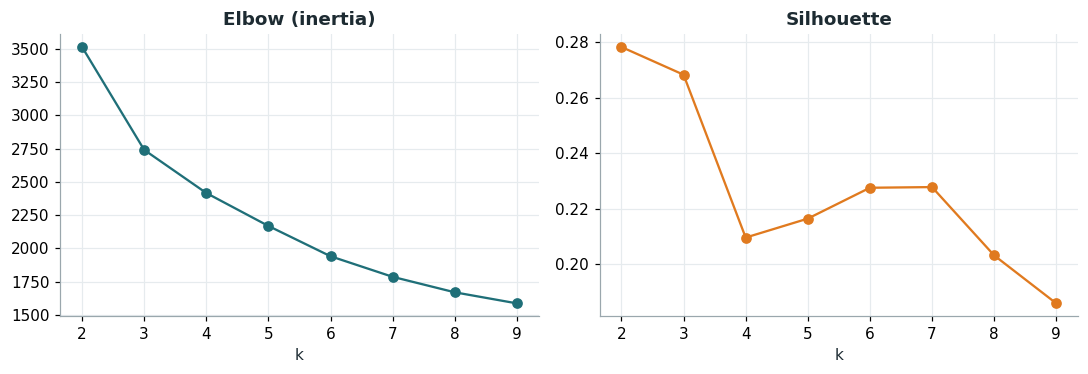

{2: np.float64(0.278), 3: np.float64(0.268), 4: np.float64(0.21), 5: np.float64(0.216), 6: np.float64(0.228), 7: np.float64(0.228), 8: np.float64(0.203), 9: np.float64(0.186)}


In [8]:
cf = ["Literacy_Rate_Effective", "Graduate_pct", "Farm_Worker_Share", "Female_Worker_Participation_Rate", "Population_Density",
      "Nearest_Railway_km", "Stations_per_1000sqkm", "Trains_Serving"]
X = d[cf].copy()
X["Literacy_Rate_Effective"] = X.Literacy_Rate_Effective.fillna(d.groupby("State_Current").Literacy_Rate_Effective.transform("median"))
for c_ in ["Population_Density", "Nearest_Railway_km", "Stations_per_1000sqkm", "Trains_Serving", "Graduate_pct"]:
    X[c_] = np.log1p(X[c_])
Xs = StandardScaler().fit_transform(X)
ks = range(2, 10); inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=20, random_state=RNG).fit(Xs); inertia.append(km.inertia_); sil.append(silhouette_score(Xs, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(list(ks), inertia, "o-", color=PAL["primary"]); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), sil, "o-", color=PAL["accent"]); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
fig.tight_layout(); save(fig, "cluster_k_selection"); plt.show()
print(dict(zip(ks, np.round(sil, 3))))

Silhouette is highest at k = 2-3 (a coarse "remote vs rest" split) and **never exceeds 0.3**: districts form a *continuum*, not natural islands.
The clusters are therefore used as a **planning typology**, not as discovered "true" groups. We choose **k = 5** because it is the
smallest k at which the *remote* districts split into literate (hill / north-east) vs deprived (tribal central-east) types and the
dense northern plains separate from the central agrarian belt – while every cluster still holds >10 % of districts.

In [9]:
K = 5
km = KMeans(K, n_init=50, random_state=RNG).fit(Xs)
d["Cluster_raw"] = km.labels_
print("k =", K, "| silhouette %.3f (k=3 would be %.3f)" % (silhouette_score(Xs, km.labels_), sil[1]), "| smallest cluster share %.0f%%" % (100 * pd.Series(km.labels_).value_counts(normalize=True).min()))
# stability: ARI against 30 re-seeded fits (10 initialisations each) and against Ward hierarchical clustering
aris = [adjusted_rand_score(km.labels_, KMeans(K, n_init=10, random_state=s).fit_predict(Xs)) for s in range(30)]
ward = AgglomerativeClustering(K, linkage="ward").fit_predict(Xs)
print("seed stability ARI: mean %.2f (min %.2f) | KMeans vs Ward ARI = %.2f  (moderate agreement: boundaries between neighbouring types are soft)" % (np.mean(aris), np.min(aris), adjusted_rand_score(km.labels_, ward)))

k = 5 | silhouette 0.217 (k=3 would be 0.268) | smallest cluster share 13%


seed stability ARI: mean 0.97 (min 0.63) | KMeans vs Ward ARI = 0.45  (moderate agreement: boundaries between neighbouring types are soft)


In [10]:
prof = pd.DataFrame(X).assign(c=km.labels_).groupby("c").mean()
prof["n"] = pd.Series(km.labels_).value_counts().sort_index()
prof["RAI"] = d.groupby("Cluster_raw").Overall_Accessibility_Index.mean()
prof["Population_Density"] = d.groupby("Cluster_raw").Population_Density.median()
prof["Nearest_Railway_km"] = d.groupby("Cluster_raw").Nearest_Railway_km.median()
prof = prof.sort_values("RAI", ascending=False)
print(prof.round(1).to_string())

   Literacy_Rate_Effective  Graduate_pct  Farm_Worker_Share  Female_Worker_Participation_Rate  Population_Density  Nearest_Railway_km  Stations_per_1000sqkm  Trains_Serving    n   RAI
c                                                                                                                                                                                      
1                     83.8           2.3               24.2                              18.5               842.8                 5.4                    2.1             4.6  117  75.7
4                     72.0           1.7               65.0                              34.3               266.3                10.7                    1.1             4.1  207  49.2
3                     67.3           1.5               62.9                              18.3               769.9                 6.5                    1.8             4.2  151  44.7
2                     77.9           1.8               51.9                     

Clusters are re-ordered by mean RAI and named from their profile (see table above).

In [11]:
order = list(prof.index)                       # ordered by mean RAI, best first
d["Cluster_rank"] = d.Cluster_raw.map({c_: i for i, c_ in enumerate(order)})
med = d.groupby("Cluster_rank").agg(lit=("Literacy_Rate_Effective", "median"), farm=("Farm_Worker_Share", "median"), fwpr=("Female_Worker_Participation_Rate", "median"),
                                   dens=("Population_Density", "median"), stn=("Stations_per_1000sqkm", "median"), rail=("Nearest_Railway_km", "median"))
def name_cluster(r, first):
    if first: return "Connected & diversified"
    if r.stn < .5 and r.rail > 30:
        return "Remote but literate (hills, north-east, islands)" if r.lit >= 75 else "Remote, farm-dependent, low literacy"
    if r.fwpr < 25 and r.dens > 500: return "Dense agrarian plains (low female work participation)"
    return "Mid-access agrarian belt"
names = {i: name_cluster(med.loc[i], i == 0) for i in med.index}
assert len(set(names.values())) == len(names), names
d["Cluster"] = d.Cluster_rank
d["Cluster_Name"] = d.Cluster_rank.map(names)
print(d.groupby(["Cluster", "Cluster_Name"]).agg(n=("District_ID", "size"), RAI=("Overall_Accessibility_Index", "mean"),
      lit=("Literacy_Rate_Effective", "median"), farm=("Farm_Worker_Share", "median"), dens=("Population_Density", "median"),
      rail_km=("Nearest_Railway_km", "median")).round(1))

                                                              n   RAI   lit  \
Cluster Cluster_Name                                                          
0       Connected & diversified                             117  75.7  83.6   
1       Mid-access agrarian belt                            207  49.2  72.1   
2       Dense agrarian plains (low female work particip...  151  44.7  67.8   
3       Remote but literate (hills, north-east, islands)     81  44.4  79.5   
4       Remote, farm-dependent, low literacy                 84  24.8  60.3   

                                                            farm   dens  \
Cluster Cluster_Name                                                      
0       Connected & diversified                             24.7  842.8   
1       Mid-access agrarian belt                            65.8  266.3   
2       Dense agrarian plains (low female work particip...  64.9  769.9   
3       Remote but literate (hills, north-east, islands)    58.1  124.7

**Reading the five types** (ordered by mean RAI):
0. **Connected & diversified** - literate, non-farm economies, stations nearby (metros, Kerala, Punjab, coastal belts).
1. **Mid-access agrarian belt** - the large middle: moderate literacy, farm-dependent, a station ~11 km away.
2. **Dense agrarian plains** - the Ganga plains: dense, rail-connected, but low literacy and very low recorded female work participation.
3. **Remote but literate** - hills, north-east and islands: literacy ~78 % but no station in the district and ~80 km to the nearest one.
4. **Remote, farm-dependent, low literacy** - the tribal central-eastern belt: literacy ~61 %, 75 % farm workers, no stations - the group that most needs investment.

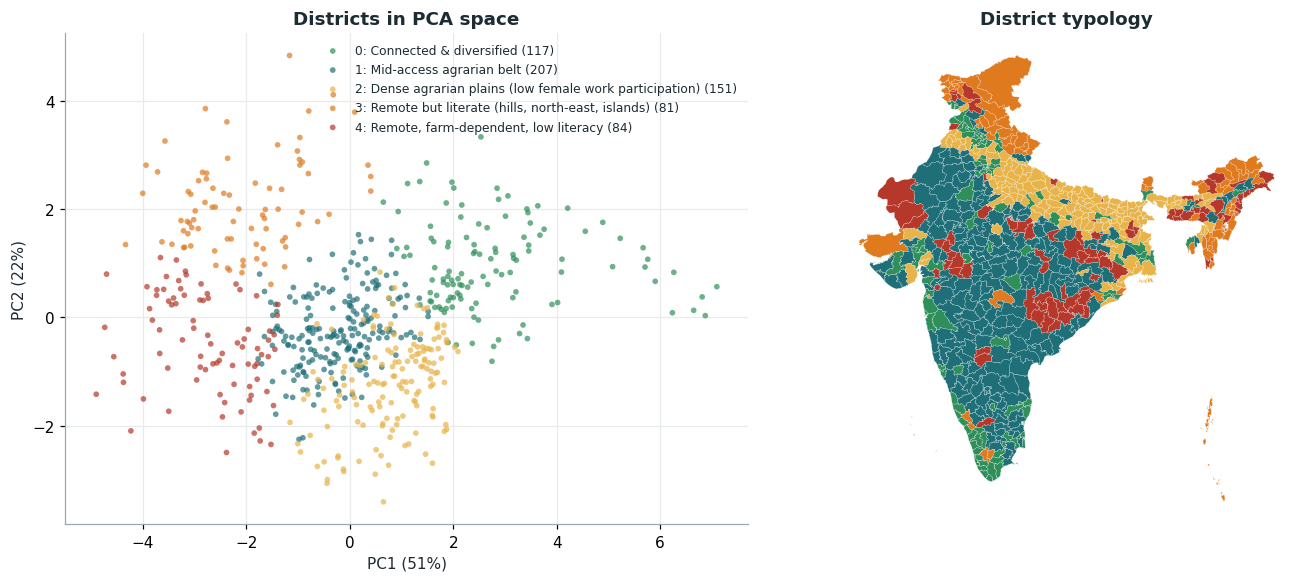

In [12]:
pca2 = PCA(2).fit(Xs); T = pca2.transform(Xs)
pal_c = [PAL["good"], PAL["primary"], "#e8b44a", PAL["accent"], PAL["bad"], "#6c5b7b", "#4a4a4a", "#9bbf85"]
fig, ax = plt.subplots(1, 2, figsize=(13, 5.4))
for i in sorted(d.Cluster.unique()):
    m_ = d.Cluster == i
    ax[0].scatter(T[m_, 0], T[m_, 1], s=14, alpha=.7, color=pal_c[i], label=f"{i}: {names[i]} ({m_.sum()})", edgecolor="none")
ax[0].set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.0f}%)"); ax[0].set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.0f}%)")
ax[0].legend(frameon=False, fontsize=8); ax[0].set_title("Districts in PCA space")
g3 = geo.merge(d[["District_ID", "Cluster"]], on="District_ID"); g3["c"] = g3.Cluster.map(lambda i: pal_c[i])
g3.plot(color=g3.c, linewidth=.1, edgecolor="white", ax=ax[1]); ax[1].set_axis_off(); ax[1].grid(False); ax[1].set_title("District typology")
fig.tight_layout(); save(fig, "cluster_map_pca"); plt.show()

## 6 · ML – predicting literacy from structural features
*Why this task?* Predicting the RAI from its own ingredients would be circular. Instead we ask: **given economy, demography, rail access and
location – but not education variables – how well can we predict literacy?** This is a stress test of how much of social access is "explained"
by structure.

The key methodological point: districts in one state are similar, so **random K-fold leaks information** between neighbours.
We compare it with **leave-states-out GroupKFold**, which mimics predicting for an unseen state.

In [13]:
feats = ["Farm_Worker_Share", "Female_Worker_Participation_Rate", "Sex_Ratio", "Young_Pop_pct", "Population_Density",
         "Nearest_Railway_km", "Stations_per_1000sqkm", "Trains_Serving", "Latitude", "Longitude"]
dm = d.dropna(subset=["Literacy_Rate_Effective"]).reset_index(drop=True)
Xm = dm[feats].copy()
for c_ in ["Population_Density", "Nearest_Railway_km", "Stations_per_1000sqkm", "Trains_Serving"]:
    Xm[c_] = np.log1p(Xm[c_])
y = dm.Literacy_Rate_Effective.values; groups = dm.State_Current.values
models = {
    "Baseline (mean)": DummyRegressor(),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))),
    "Random Forest": RandomForestRegressor(400, min_samples_leaf=3, random_state=RNG, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(max_depth=4, learning_rate=.05, max_iter=300, random_state=RNG),
}
def evaluate(cv, grp=None):
    out = {}
    for n, mdl in models.items():
        pred = cross_val_predict(mdl, Xm, y, cv=cv, groups=grp)
        out[n] = dict(R2=r2_score(y, pred), MAE=mean_absolute_error(y, pred), RMSE=mean_squared_error(y, pred) ** .5)
    return pd.DataFrame(out).T, pred
rand_res, _ = evaluate(KFold(5, shuffle=True, random_state=RNG))
grp_res, _ = evaluate(GroupKFold(6), groups)
cmp = pd.concat({"random 5-fold": rand_res, "states held out (GroupKFold)": grp_res}, axis=1).round(3)
print(cmp.to_string())

                  random 5-fold                states held out (GroupKFold)               
                             R2    MAE    RMSE                           R2    MAE    RMSE
Baseline (mean)          -0.002  8.436  10.499                       -0.053  8.689  10.761
Ridge                     0.531  5.438   7.178                        0.422  6.101   7.972
Random Forest             0.698  4.340   5.760                        0.470  5.817   7.633
Gradient Boosting         0.727  4.126   5.476                        0.501  5.692   7.405


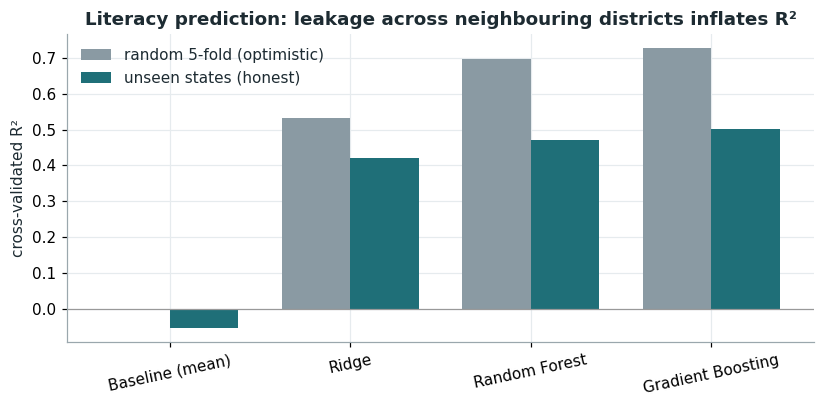

In [14]:
fig, ax = plt.subplots(figsize=(7.6, 3.8))
idx = np.arange(len(rand_res)); wd = .38
ax.bar(idx - wd/2, rand_res.R2, wd, color=PAL["muted"], label="random 5-fold (optimistic)")
ax.bar(idx + wd/2, grp_res.R2, wd, color=PAL["primary"], label="unseen states (honest)")
ax.set_xticks(idx); ax.set_xticklabels(rand_res.index, rotation=12); ax.axhline(0, color="#999", lw=.8); ax.set_ylabel("cross-validated R²")
ax.set_title("Literacy prediction: leakage across neighbouring districts inflates R²"); ax.legend(frameon=False)
fig.tight_layout(); save(fig, "ml_cv_comparison"); plt.show()

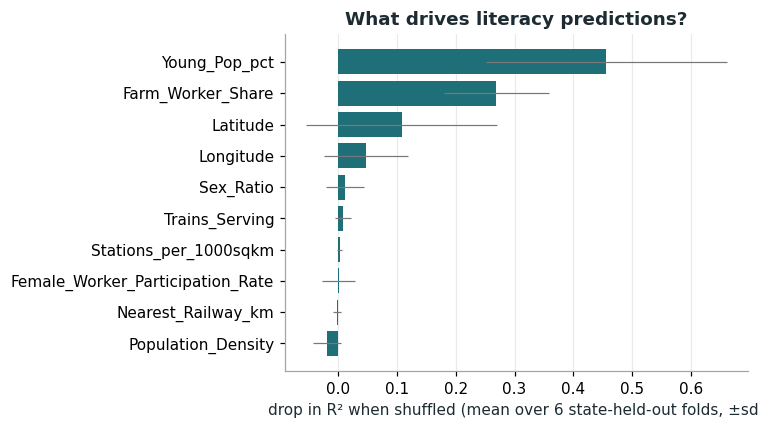

Young_Pop_pct                       0.456
Farm_Worker_Share                   0.269
Latitude                            0.108
Longitude                           0.047
Sex_Ratio                           0.011
Trains_Serving                      0.008
Stations_per_1000sqkm               0.002
Female_Worker_Participation_Rate    0.000
Nearest_Railway_km                 -0.002
Population_Density                 -0.019


In [15]:
# permutation importance, computed on the test fold of every state-held-out split and averaged
imps = []
for tr, te in GroupKFold(6).split(Xm, y, groups):
    rf = RandomForestRegressor(400, min_samples_leaf=3, random_state=RNG, n_jobs=-1).fit(Xm.iloc[tr], y[tr])
    imps.append(permutation_importance(rf, Xm.iloc[te], y[te], n_repeats=15, random_state=RNG, n_jobs=-1).importances_mean)
imp = pd.Series(np.mean(imps, axis=0), index=feats); sd = pd.Series(np.std(imps, axis=0), index=feats)
imp, sd = imp.sort_values(), sd.reindex(imp.sort_values().index)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index, imp.values, xerr=sd.values, color=PAL["primary"], error_kw=dict(lw=.8, ecolor="#777"))
ax.set_xlabel("drop in R² when shuffled (mean over 6 state-held-out folds, ±sd)"); ax.set_title("What drives literacy predictions?"); ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "ml_importance"); plt.show()
print(imp.sort_values(ascending=False).round(3).to_string())

**Reading.** Even with *no* education inputs a gradient-boosting model explains **~50 %** of literacy variation in **unseen states** (MAE ~5.7 pp vs 8.7 for a mean baseline).
Random 5-fold CV reports R2 ~ 0.73 - an **inflation of ~0.2** caused by neighbouring districts of the same state appearing in both train and test sets. We report the honest figure.
The strongest predictors are the **young-population share** (the demographic transition: low-fertility, high-literacy districts) and **farm dependence**; rail variables add almost nothing, consistent with H1 in notebook 03.
These are **associations**, not causes.

## 7 · Export the analytical master

In [16]:
ANA = ["NonFarm_Worker_Share", "Education_Access_Score", "Transport_Access_Score", "Health_Access_Score", "Livelihood_Access_Score",
       "Overall_Accessibility_Index", "RAI_Rank", "Access_Tier", "Priority_Group", "LISA_Cluster", "Cluster", "Cluster_Name"]
d["Source_Index_Version"] = "RAI v1.0 (weights E.30 T.30 H.20 L.20)"
master = d[list(df.columns) + ANA + ["Source_Index_Version"]].copy()
master = master.round({c_: 3 for c_ in master.select_dtypes("float").columns})
master.to_csv(FINAL / "RuralReach_Master.csv", index=False)
print(master.shape, "->", FINAL / "RuralReach_Master.csv")

summary = dict(
    n_districts=len(d), rai_mean=float(d.Overall_Accessibility_Index.mean()),
    rank_rho_equal=float(rho["equal weights"]), rank_rho_pca=float(rho["PCA loadings"]),
    rank_rho_random_median=float(np.median(rd)), rank_rho_random_p5=float(np.percentile(rd, 5)),
    moran_rai=float(res["Overall_Accessibility_Index"][0]), moran_lit=float(res["Literacy_Rate_Effective"][0]),
    k=int(K), silhouette=float(silhouette_score(Xs, km.labels_)), ari_seed=float(np.mean(aris)), ari_ward=float(adjusted_rand_score(km.labels_, ward)),
    ml_random=rand_res.R2.round(3).to_dict(), ml_group=grp_res.R2.round(3).to_dict(), ml_group_mae=grp_res.MAE.round(2).to_dict(),
    critical_districts=int(d.Priority_Group.str.startswith("1").sum()),
    critical_population_m=float(d.loc[d.Priority_Group.str.startswith("1"), "Population"].sum() / 1e6),
    cluster_names={int(k): v for k, v in names.items()},
)
json.dump(summary, open(PROCESSED / "results_summary.json", "w"), indent=1)
pd.DataFrame(names.items(), columns=["Cluster", "Name"]).to_csv(PROCESSED / "cluster_names.csv", index=False)
summary

(640, 95) -> C:\Users\Siddhesh\RuralReach\final\RuralReach_Master.csv


{'n_districts': 640,
 'rai_mean': 49.1750552255672,
 'rank_rho_equal': 0.9856076003603526,
 'rank_rho_pca': 0.9476418246870723,
 'rank_rho_random_median': 0.89772447411981,
 'rank_rho_random_p5': 0.6600150169739185,
 'moran_rai': 0.5359940702059897,
 'moran_lit': 0.6228396776916563,
 'k': 5,
 'silhouette': 0.21709401902805112,
 'ari_seed': 0.9705218105728526,
 'ari_ward': 0.4544409678954288,
 'ml_random': {'Baseline (mean)': -0.002,
  'Ridge': 0.531,
  'Random Forest': 0.698,
  'Gradient Boosting': 0.727},
 'ml_group': {'Baseline (mean)': -0.053,
  'Ridge': 0.422,
  'Random Forest': 0.47,
  'Gradient Boosting': 0.501},
 'ml_group_mae': {'Baseline (mean)': 8.69,
  'Ridge': 6.1,
  'Random Forest': 5.82,
  'Gradient Boosting': 5.69},
 'critical_districts': 146,
 'critical_population_m': 188.149954,
 'cluster_names': {0: 'Connected & diversified',
  1: 'Mid-access agrarian belt',
  2: 'Dense agrarian plains (low female work participation)',
  3: 'Remote but literate (hills, north-east, isl